In [19]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph,START,END
from langchain_groq import ChatGroq
from dotenv import load_dotenv

In [20]:
load_dotenv

<function dotenv.main.load_dotenv(dotenv_path: str | ForwardRef('os.PathLike[str]') | None = None, stream: IO[str] | None = None, verbose: bool = False, override: bool = False, interpolate: bool = True, encoding: str | None = 'utf-8') -> bool>

In [21]:
class SubState(TypedDict):
    input_text:str
    translated_text:str

In [22]:
subgraph_llm=ChatGroq(model='openai/gpt-oss-20b')

In [23]:
def translate_text(state: SubState):
    prompt = f"""
Translate the following text to Hindi.
Keep it natural and clear. Do not add extra content.

Text:
{state['input_text']}
""".strip()

    translated_text = subgraph_llm.invoke(prompt).content

    return {'translated_text': translated_text}

In [24]:
subgraph_builder=StateGraph(SubState)
subgraph_builder.add_node('translate_text',translate_text)
subgraph_builder.add_edge(START,'translate_text')
subgraph_builder.add_edge('translate_text',END)
subgraph=subgraph_builder.compile()

In [25]:
class ParentState(TypedDict):
    question:str
    answer_eng:str
    answer_hin:str

In [26]:
parent_llm=ChatGroq(model='openai/gpt-oss-20b')


In [27]:
def generate_answer(state:ParentState):
    answer=parent_llm.invoke(f"You are a helpful assistant.Answer clearly.\n\nQuestion:{state['question']}").content
    return {'answer_eng':answer}

In [28]:
def translate_answer(state:ParentState):
    #calll subgraph
    result=subgraph.invoke({
        'input_text':state['answer_eng']
    })
    return {'answer_hin':result['translated_text']}

In [29]:
parent_builder=StateGraph(ParentState)
parent_builder.add_node("answer",generate_answer)
parent_builder.add_node("translate",translate_answer)
parent_builder.add_edge(START,'answer')
parent_builder.add_edge('answer','translate')
parent_builder.add_edge('translate',END)


In [30]:
graph=parent_builder.compile()

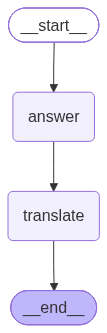

In [31]:
graph

In [32]:
graph.invoke({'question':'What is differnce between classical and Quantum Physics.explain with a example'})

{'question': 'What is differnce between classical and Quantum Physics.explain with a example',
 'answer_eng': '**Classical physics** (Newtonian mechanics, electromagnetism, thermodynamics, etc.) describes the world in terms of:\n\n| Feature | Classical view |\n|---------|----------------|\n| **Deterministic** | A system’s future state is uniquely fixed by its present state and the laws of motion. |\n| **Continuity** | Physical quantities (position, velocity, energy) can take any value within a continuous range. |\n| **Locality** | Objects interact only with their immediate surroundings; signals travel at finite speed (e.g., speed of light). |\n| **Superposition** | The state of a system is a single definite configuration; you can’t have two mutually exclusive states at once. |\n| **Measurement** | Observing a system doesn’t disturb it; you can know position and velocity simultaneously. |\n\n---\n\n**Quantum physics** (quantum mechanics, quantum field theory) replaces these assumptions 